In [43]:
!unzip archive.zip

Archive:  archive.zip
replace processed_repetitions/2d_joints/Ex1/PM_001_rep10_label0.npy? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep10_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep2_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep3_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep4_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep5_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep6_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep7_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep8_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep9_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_00

In [44]:
path = "/content/processed_repetitions/2d_joints/Ex4"

In [45]:
import subprocess, sys
for pkg in ("optuna", "xgboost", "lightgbm"):
    try:
        __import__(pkg)
    except ModuleNotFoundError:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        except Exception:
            pass
import os, re, warnings
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from collections import defaultdict
from dataclasses import dataclass

import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.metrics import (matthews_corrcoef, roc_auc_score, roc_curve,
                             confusion_matrix, precision_score,
                             pairwise_distances)
from sklearn.model_selection import train_test_split
from scipy.signal import savgol_filter

warnings.filterwarnings("ignore")

In [46]:
SEED      = 42
N_TRIALS  = 40
SAVE_PATH = os.getcwd()

def set_seed(s):
    np.random.seed(s)

set_seed(SEED)

In [47]:
FNAME_RE = re.compile(r"PM_(\w+?)_rep(\d+)_label(\d)\.npy")

def build_records(exercise_dir):
    records = []
    for fname in os.listdir(exercise_dir):
        m = FNAME_RE.match(fname)
        if not m:
            continue
        person, rep, label = m.group(1), int(m.group(2)), int(m.group(3))
        records.append({"path": os.path.join(exercise_dir, fname),
                        "person_id": person, "rep": rep, "label": label})
    return records

### person-disjoint deterministic split (seed 42, stratified by flawed share)


In [48]:
def subject_split(records, test_size=0.2, seed=42):
    """Person-disjoint train/test split, deterministic, percentage-based."""
    persons = sorted({r["person_id"] for r in records})
    per_person = defaultdict(list)
    for r in records:
        per_person[r["person_id"]].append(r["label"])

    flawed_share = np.array([1.0 - (sum(per_person[p]) / len(per_person[p])) for p in persons])
    strata = np.digitize(flawed_share, [0.001, 0.25, 0.75, 0.999])
    persons_arr = np.array(persons)

    try:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, stratify=strata, shuffle=True)
    except ValueError:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, shuffle=True)

    train_set = set(train_persons.tolist())
    train = [r for r in records if r["person_id"] in train_set]
    test  = [r for r in records if r["person_id"] not in train_set]

    print(f"[split seed={seed} test_size={test_size}] "
          f"train={len(train_set)} persons, test={len(test_persons)} persons | "
          f"train reps P={sum(r['label'] for r in train)}, test reps P={sum(r['label'] for r in test)}")
    return train, test

In [49]:
records = build_records(path)
train, test = subject_split(records, 0.2, 42)

[split seed=42 test_size=0.2] train=8 persons, test=3 persons | train reps P=70, test reps P=7


### joints / bones (shared 26-joint REHAB24-6 rig; same indices as the era)

In [50]:
JN = {
    "Hips": 0, "Spine": 1, "Spine1": 2, "Neck": 3, "Head": 4, "Head_end": 5,
    "LeftShoulder": 6, "LeftArm": 7, "LeftForeArm": 8, "LeftHand": 9, "LeftHand_end": 10,
    "RightShoulder": 11, "RightArm": 12, "RightForeArm": 13, "RightHand": 14, "RightHand_end": 15,
    "LeftUpLeg": 16, "LeftLeg": 17, "LeftFoot": 18, "LeftToeBase": 19, "LeftToeBase_end": 20,
    "RightUpLeg": 21, "RightLeg": 22, "RightFoot": 23, "RightToeBase": 24, "RightToeBase_end": 25,
}
JN_R = {v: k for k, v in JN.items()}

# exact v22 BONES (26 joints; the plotting bone set) + E3 V8 full chain (identical)
BONES = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5),
         (2, 6), (6, 7), (7, 8), (8, 9), (9, 10),
         (2, 11), (11, 12), (12, 13), (13, 14), (14, 15),
         (0, 16), (16, 17), (17, 18), (18, 19), (19, 20),
         (0, 21), (21, 22), (22, 23), (23, 24), (24, 25)]

In [51]:
# ghost renderer constants — exact V8 values
K_RES   = 32                 # time-normalized ghost/rep frames
F_POINTS = (0.12, 0.25, 0.4, 0.55, 0.7, 0.85)   # validation-pack progress fractions
F_DEEP  = (0.08, 0.18, 0.3, 0.42, 0.55, 0.7, 0.85, 0.96)  # deep-dive panels
ARROW_T = 0.18               # torso units — green arrow cut-off (E3 V8)

### normalization + smoothing + resampling

In [52]:
N_FRAMES = 90
SGF_WIN  = 11
MIN_PHASE = 6

def normalize_clip(arr):
    "(frames,26,2) pixels -> hips-centered / torso-length-scaled per frame (E3)."
    arr = np.asarray(arr, np.float64)
    hips, neck = arr[:, JN["Hips"], :], arr[:, JN["Neck"], :]
    torso = np.linalg.norm(neck - hips, axis=1)
    torso = np.where(torso < 1e-6, 1e-6, torso)
    return (arr - hips[:, None, :]) / torso[:, None, None]

def resample_pose(seq, n=N_FRAMES):
    T = seq.shape[0]
    if T == n:
        return seq.copy()
    xs, xd = np.arange(T), np.linspace(0, T - 1, n)
    return np.stack([np.stack([np.interp(xd, xs, seq[:, j, c]) for c in range(2)],
                               axis=-1) for j in range(seq.shape[1])], axis=1)

def smooth_pose(norm, win=SGF_WIN):
    T = norm.shape[0]
    w = min(win if win % 2 == 1 else win + 1, (T // 2) * 2 + 1)
    if w < 5:
        return norm
    return np.stack([savgol_filter(norm[:, j, :], w, 2, axis=0) for j in range(norm.shape[1])], 1)

def resample_flat(mat, n=8):
    """nearest-index resample of a (T,F) matrix to n frames (E3 features_v4.resample_to)."""
    T = mat.shape[0]
    if T == n:
        return mat.copy()
    idx = np.clip(np.round(np.linspace(0, T - 1, n)).astype(int), 0, T - 1)
    return mat[idx]

def resample_time_norm(norm, k=K_RES):
    """start/end-anchored time-normalized render grid (V8 resample_pose)."""
    return np.stack([resample_flat(norm, k).reshape(k, 26, 2)])[0] if norm.shape[0] != k \
        else norm.copy()

### angle primitives (E3 `common.features` — degrees, y-down image coords)


In [53]:
def angle_3pt(a, b, c):
    """Angle ABC at vertex b (frame arrays ok), degrees."""
    ab, bc = np.asarray(a, float) - b, np.asarray(c, float) - b
    denom = (np.linalg.norm(ab, axis=-1) * np.linalg.norm(bc, axis=-1)) + 1e-9
    return np.degrees(np.arccos(np.clip(np.sum(ab * bc, axis=-1) / denom, -1.0, 1.0)))

def trunk_vertical_angle(norm):
    """Spine→Neck segment vs UP (0,-1), degrees (E3 trunk_angle)."""
    v = norm[:, JN["Neck"], :] - norm[:, JN["Spine"], :]
    n = np.linalg.norm(v, axis=-1)
    up = np.array([0.0, -1.0])
    cs = np.clip(v @ up / np.maximum(n, 1e-9), -1.0, 1.0)
    return np.degrees(np.arccos(cs))

def side_series(norm, pre):
    leg = lambda a, b, c: angle_3pt(norm[:, a, :], norm[:, b, :], norm[:, c, :])
    hip, kn, ft = JN[f"{pre}UpLeg"], JN[f"{pre}Leg"], JN[f"{pre}Foot"]
    return {
        "leg_elevation": leg(JN["Hips"], hip, kn),   # Hips→UpLeg→Leg (elevation)
        "knee_angle":    leg(hip, kn, ft),           # UpLeg→Leg→Foot
        "pelvic_tilt":   leg(JN["Spine"], JN["Hips"], hip),
        "plane_deviation": leg(JN["Spine"], hip, kn),
    }

def channel_series(norm):
    """Per-frame channels for Ex4 (both eras unified, E3 side rule):
    exercised leg = the side with the larger elevation range (v22 mirror-
    canonicalization substitutes the subtype flag; era Ex4 found the flag ~chance
    (0.62) so the range heuristic is the kept rule).
    Returns (C7, side): rows = leg_elev, trunk, pelvic_tilt, knee,
    leg_plane (exercised side), foot_below_hip (v22) + frontness_span (E3 c3)."""
    per = {s: side_series(norm, {"left": "Left", "right": "Right"}[s]) for s in ("left", "right")}
    best = max(("left", "right"), key=lambda s: np.ptp(per[s]["leg_elevation"]))
    trunk = trunk_vertical_angle(norm)
    tl = np.linalg.norm(norm[:, JN["Neck"], :] - norm[:, JN["Hips"], :], axis=-1) + 1e-6
    foot_y = norm[:, JN[{"left": "LeftFoot", "right": "RightFoot"}[best]], 1]
    fbh = np.clip((norm[:, JN["Hips"], 1] - foot_y) / (2.0 * tl), 0, None)
    front = np.abs(norm[:, JN["LeftShoulder"], 0] - norm[:, JN["RightShoulder"], 0])
    C = np.stack([
        per[best]["leg_elevation"], trunk, per[best]["pelvic_tilt"],
        per[best]["knee_angle"], per[best]["plane_deviation"], fbh,
    ], axis=1)
    return C, front, best

CH_NAMES   = ["leg_elev", "trunk", "pelvic_tilt", "knee", "leg_plane", "foot_below_hip"]
CRM_NAMES  = ["trunk_angle", "pelvic_tilt", "knee_angle", "plane_deviation"]  # V7 critique set (Ex4 drops leg_elevation)


In [54]:
### v22 `ex_channel_stats` — the **117-dim scalar feature vector** for Ex4
# whole(7) + early(6) + late(6) = 19 per channel × 6 channels + ext_t_norm, prim_std,
# len_norm. Exactly `model_test_v22.py` CELL 8 for ex==4 (MODE 'up', leg_elev primary).


In [55]:
def derivative(x, h=1.0):
    d = np.zeros_like(x); d[1:-1] = (x[2:] - x[:-2]) / (2 * h); d[0], d[-1] = d[1], d[-2]
    return d

def phase_bounds(p, mode="up"):
    trend = float(p[-1] - p[0])
    s = 1.0 if mode == "up" else -1.0
    t_mid = int(np.argmax(s * (p - p[0]))) if trend * s >= 0 else int(np.argmin(s * (p - p[0])))
    return int(np.clip(t_mid, MIN_PHASE, len(p) - MIN_PHASE))

def phase_stats(x):
    if len(x) < MIN_PHASE:
        return [0.0] * 6
    d = derivative(np.asarray(x, float))
    return [float(np.nanmean(x)), float(np.nanmin(x)), float(np.nanmax(x)),
            float(np.nanmax(x) - np.nanmin(x)), float(np.nanmean(np.abs(d))),
            float(np.nanmax(np.abs(d)))]

def scalar_features(norm):
    """(T,26,2) normalized -> (117,) vector + (117,) names + diagnostics."""
    C, front, side = channel_series(norm)
    p_idx = 0                                    # leg_elev is PRIMARY (v22)
    t_mid = phase_bounds(np.nan_to_num(C[:, p_idx]))
    feats, fnames = [], []
    for i, nm in enumerate(CH_NAMES):
        col = np.nan_to_num(C[:, i])
        whole = phase_stats(col) + [float(np.abs(np.diff(col)).mean())]
        ph0, ph1 = phase_stats(col[:t_mid]), phase_stats(col[t_mid:])
        feats += whole + ph0 + ph1
        fnames += ([f"{nm}_w{m}" for m in range(7)] +
                   [f"{nm}_p0{m}" for m in range(6)] +
                   [f"{nm}_p1{m}" for m in range(6)])
    pcol = np.nan_to_num(C[:, p_idx])
    pol = float(np.sign(np.mean(np.diff(pcol)))) or 1.0
    feats += [float(np.argmax(pol * pcol) / len(pcol)), float(np.nanstd(pcol)), 1.0]
    fnames += ["ext_t_norm", "prim_std", "len_norm"]
    return np.nan_to_num(np.array(feats, float)), fnames, C, front, side, t_mid

def series_statistics(mat):
    """E3 series_stats: (T,) per-series -> (5,) mean/std/min/max/range."""
    return np.array([mat.mean(0), mat.std(0), mat.min(0), mat.max(0), np.ptp(mat, axis=0)]).ravel()

### feature cache — built once per rep (not inside Optuna)

In [56]:
def build_rep(arr):
    norm = normalize_clip(arr)
    tpl  = smooth_pose(resample_pose(norm))                 # resampled+smoothed (90,26,2)
    x117, xnames, C, front, side, t_mid = scalar_features(tpl)
    # c3 rep matrix: 6 series (exercised slot + trunk + frontness) -> summ|vel|flat8
    S = np.stack([C[:, 0], C[:, 1], C[:, 2], C[:, 3], C[:, 4], front], axis=1)
    c3 = np.concatenate([series_statistics(S), series_statistics(np.diff(S, axis=0)),
                         resample_flat(S, 8).reshape(-1)])   # 30+30+48 = 108
    # V7 critique features: trained-set stats of the 4 critique series
    rule = np.concatenate([series_statistics(C[:, j:j + 1]) for j in (1, 2, 3)])
    return dict(template=tpl, x117=x117, xnames=xnames, C=C, S6=S, c3=c3, rule=rule,
                side=side, t_mid=t_mid, fname=os.path.basename(getattr(arr, "name", "") or ""))

def rep_c3_names():
    base = ["leg_elev", "trunk", "pelvic_tilt", "knee", "leg_plane", "frontness"]
    return ([f"{n}_{s}" for n in base for s in ("mean", "std", "min", "max", "range")] +
            [f"d{n}_{s}" for n in base for s in ("mean", "std", "min", "max", "range")] +
            [f"f8_{n}_{f}_{k}" for n in base for f in range(8) for k in ("x",)])

def enrich(records):
    out = []
    for r in sorted(records, key=lambda r: (r["person_id"], r["rep"])):
        arr = np.load(r["path"])
        if arr.ndim != 3 or arr.shape[0] < 10:
            continue
        b = build_rep(arr)
        rec = dict(r)
        rec.update(b)
        out.append(rec)
    return out

feat_train = enrich(train)
feat_test  = enrich(test)
print(f"cached features: train={len(feat_train)} reps, test={len(feat_test)} reps | "
      f"x117 dims={feat_train[0]['x117'].shape[0]}, c3 dims={feat_train[0]['c3'].shape[0]}")

# quick sanity: exercised sides + phase split + frontness ranges on train
print("side counts:", {s: sum(1 for r in feat_train if r['side'] == s) for s in ('left', 'right')})
print("t_mid range: ",
      min(r['t_mid'] for r in feat_train), "to", max(r['t_mid'] for r in feat_train))


cached features: train=110 reps, test=16 reps | x117 dims=117, c3 dims=108
side counts: {'left': 61, 'right': 49}
t_mid range:  6 to 84


### metrics (positive class = label 1 = PERFECT)

In [57]:
@dataclass
class ExConfig:
    fbeta: float = 2.0

def compute_all_metrics(y_true, y_pred, y_proba, beta=2.0):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1); acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-6)
    fb = (1 + beta ** 2) * prec * rec / max(beta ** 2 * prec + rec, 1e-6)
    mcc = float(matthews_corrcoef(y_true, y_pred)) if len(np.unique(y_true)) >= 2 else 0.0
    auroc = float(roc_auc_score(y_true, y_proba)) if len(np.unique(y_true)) >= 2 else 0.0
    return {"accuracy": acc, "balanced_acc": (rec + spec) / 2.0,
            "precision": prec, "recall": rec, "sensitivity": rec,
            "specificity": spec, "f1": f1, f"f{int(beta)}": fb,
            "mcc": mcc, "auroc": auroc, "tp": tp, "tn": tn, "fp": fp, "fn": fn}

def print_confusion_matrix(y_true, y_pred, exercise_id):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    print(f"\n  [{exercise_id}] Confusion Matrix:")
    print("                  Predicted PASS  Predicted FAIL")
    if cm.shape == (2, 2):
        tp, fn = cm[0, 0], cm[0, 1]
        fp, tn = cm[1, 0], cm[1, 1]
        print(f"  True PERFECT:  {tp:4d} ({tp / max(tp + fn, 1) * 100:5.1f}%)    "
              f"{fn:4d} ({fn / max(tp + fn, 1) * 100:5.1f}%)")
        print(f"  True FLAWED:   {fp:4d} ({fp / max(tn + fp, 1) * 100:5.1f}%)    "
              f"{tn:4d} ({tn / max(tn + fp, 1) * 100:5.1f}%)")
    else:
        print(f"  {cm}")

def plot_roc_curve(y_true, y_proba, exercise_id, save_path=SAVE_PATH):
    if len(np.unique(y_true)) < 2:
        return None
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auroc = roc_auc_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot(fpr, tpr, color="steelblue", lw=2.5, label=f"ROC (AUROC={auroc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
    ax.set_xlabel("FPR (1-Specificity)", fontsize=9)
    ax.set_ylabel("TPR (Sensitivity)", fontsize=9)
    ax.set_title(f"{exercise_id} — ROC Curve", fontsize=10)
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.4)
    fpath = os.path.join(save_path, f"{exercise_id}_roc.png")
    plt.savefig(fpath, dpi=100, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

### generic runner: Optuna (TPE, seed) → finalize → OOF-Platt gate → flood-proof OOF-quantile cut + **era cut** (v22 MCC-graded sweep, precision floor)

In [58]:
class ArchSpec:
    name = "arch"
    supervised = False
    min_precision = 0.55            # Ex4 OOF precision floor (era exact)
    def search_space(self, trial): raise NotImplementedError
    def build(self, rows, p, seed): raise NotImplementedError
    def score_rows(self, model, rows): raise NotImplementedError
    def ship_scores(self, model, rows): return None   # P(flawed) for the era cut

# era cut: v22 threshold_mcc — MCC-graded sweep with graded precision-floor penalty
def threshold_mcc_graded(p_flawed, y_flawed, min_prec=0.55):
    """Cut on P(flawed): sweep 91 candidates; score = MCC − 2×(min_prec−precision)
    when below the floor; ties prefer the HIGHER cut. Landed 'floor_ok' bool."""
    from sklearn.metrics import recall_score
    cands = []
    for t in np.linspace(0.05, 0.95, 91):
        pred = (p_flawed >= t).astype(int)          # FAIL if p_flawed >= t
        if pred.sum() == 0 or pred.sum() == len(pred):
            continue
        prec = precision_score(y_flawed, pred, zero_division=0)
        mcc = matthews_corrcoef(y_flawed, pred) if len(set(pred)) > 1 else 0.0
        score = mcc - (2.0 * (min_prec - prec) if prec < min_prec else 0.0)
        cands.append((score, float(t), mcc, prec, bool(prec >= min_prec and mcc > 0.15)))
    if not cands:
        return 0.5, False
    best_score = max(c[0] for c in cands)
    pool = [c for c in cands if c[0] >= best_score - 1e-12]
    best = max(pool, key=lambda c: (c[1], c[0]))
    return best[1], bool(best[4])

In [59]:
def run_optuna_for(spec, rows, n_trials=N_TRIALS):
    """Inner person-disjoint split; objective = MCC(cut) + AUROC on inner-val."""
    persons = sorted({r["person_id"] for r in rows})
    rng = np.random.RandomState(SEED)
    val_p = set(persons[i] for i in rng.permutation(len(persons))[:max(2, len(persons) // 5)])
    tr_r = [r for r in rows if r["person_id"] not in val_p]
    va_r = [r for r in rows if r["person_id"] in val_p]
    print(f"  optuna inner split: train reps={len(tr_r)} val reps={len(va_r)} "
          f"(person-disjoint: {len({r['person_id'] for r in tr_r})}/{len(val_p)} persons)")

    def objective(trial):
        p = spec.search_space(trial)
        fit_rows = tr_r if _is_sup(spec) else [r for r in tr_r if r["label"] == 1]
        model = spec.build(fit_rows, p, SEED)
        s_tr = spec.score_rows(model, tr_r)
        s_va = spec.score_rows(model, va_r)
        y_tr = np.array([r["label"] for r in tr_r])
        y_va = np.array([r["label"] for r in va_r])
        thr = np.percentile(s_tr[y_tr == 1], p.get("q", 80.0)) if _is_sup(spec) \
            else np.percentile(s_tr, p.get("q", 80.0))
        mcc = matthews_corrcoef(1 - y_va, (s_va <= thr).astype(int))
        auroc = roc_auc_score(1 - y_va, -s_va)
        return mcc + auroc

    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner())
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    full_p = spec.search_space(optuna.trial.FixedTrial(study.best_params))
    study.set_user_attr("best_full_params", full_p)
    return study

def _is_sup(spec):
    return bool(getattr(spec, "supervised", False))

def finalize_for(spec, study, feat_train, feat_test):
    p = dict(study.user_attrs.get("best_full_params") or study.best_params)
    Xc_rows = [r for r in feat_train if r["label"] == 1]
    set_seed(SEED)
    fit_rows = feat_train if _is_sup(spec) else Xc_rows
    model = spec.build(fit_rows, p, SEED)
    s_c = spec.score_rows(model, Xc_rows)
    thr = float(np.percentile(s_c, p.get("q", 80.0)))
    print(f"provisional score threshold: {thr:.6f}")

    st = spec.score_rows(model, feat_test)
    yt = np.array([r["label"] for r in feat_test])
    m = compute_all_metrics(yt, (st <= thr).astype(int), -st)
    print_confusion_matrix(yt, (st <= thr).astype(int), spec.name)
    plot_roc_curve(yt, -st, spec.name)
    return dict(spec=spec, params=p, model=model, threshold=thr,
                metrics=m, scores=st, y=yt, rows=list(feat_test), study=study)

def platt_fit_oof_for(spec, study, feat_train, n_folds=2):
    """Person-disjoint folds; OOF Platt fitted on RAW scores, target = FLAWED.
    Same degenerate guards as the era (slope <= tiny, span < 0.15 -> identity)."""
    p = dict(study.user_attrs.get("best_full_params") or study.best_params)
    persons = sorted({f["person_id"] for f in feat_train})
    assert len(persons) >= 2 * n_folds, "too few persons for OOF-Platt folds"
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(persons))
    folds = [set(np.array(persons)[c].tolist()) for c in np.array_split(perm, n_folds)]

    pl, ys = [], []
    for ps in folds:
        tr_r = [f for f in feat_train if f["person_id"] not in ps]
        te_r = [f for f in feat_train if f["person_id"] in ps]
        fit_rows = tr_r if _is_sup(spec) else [r for r in tr_r if r["label"] == 1]
        model = spec.build(fit_rows, p, SEED)
        s = spec.score_rows(model, te_r)
        pl += [s]; ys += [1 - r["label"] for r in te_r]      # flawed = 1
    pl, ys = np.concatenate(pl), np.array(ys, dtype=float)

    if len(set(ys)) < 2 or np.nanstd(pl) < 1e-9:
        a, b, p_flawed = 1.0, 0.0, pl
    else:
        lr = LogisticRegression(C=1e5, max_iter=1000).fit(pl.reshape(-1, 1), ys.astype(int))
        a = float(lr.coef_[0][0]); b = float(lr.intercept_[0])
        p_flawed = platt_p_flawed({"a": a, "b": b}, pl)
        if a <= 1e-6 or (np.nanpercentile(p_flawed, 95) - np.nanpercentile(p_flawed, 5)) < 0.15:
            a, b, p_flawed = 1.0, 0.0, pl
    auroc = roc_auc_score(ys, p_flawed) if len(set(ys)) == 2 else float("nan")
    gate = "PASS" if (auroc > 0.5 and a > 0) else "*** FAIL — do not ship verdicts ***"
    print(f"  Platt a={a:.3f} b={b:.3f} | OOF AUROC(flawed)={auroc:.3f} [{gate}] | "
          f"P(flawed): correct={p_flawed[ys == 0].mean():.3f} flawed={p_flawed[ys == 1].mean():.3f}")
    return {"a": a, "b": b, "oof_auroc": auroc, "oof_p": p_flawed, "oof_y": ys}

def platt_p_flawed(platt, scores):
    z = platt["a"] * np.asarray(scores, float) + platt["b"]
    return 1.0 / (1.0 + np.exp(-z))

In [60]:
TRAIN_CORRECT = [r for r in feat_train if r["label"] == 1]

# population reference (ghost retrieval + personal bank share these):
CORRECT_X = np.stack([r["x117"] for r in TRAIN_CORRECT])
POP_LO, POP_HI = np.percentile(CORRECT_X, 25, 0), np.percentile(CORRECT_X, 75, 0)
POP_MED   = np.median(CORRECT_X, 0)
POP_BAND  = np.maximum(POP_HI - POP_LO, 1e-9)

# per-feature "wrong side" sign (era: corr of feature with correct-label)
_ytr = np.array([r["label"] for r in feat_train], int)
_Xtr = np.nan_to_num(np.stack([r["x117"] for r in feat_train]))
corrfeats = []
for j in range(_Xtr.shape[1]):
    col = _Xtr[:, j]
    corrfeats.append(0.0 if col.std() < 1e-9 else float(np.corrcoef(col, _ytr)[0, 1]))
FEAT_CORR = np.array(corrfeats)

def train_channel_banks():
    """v22 train_side_bank: per named channel, (p5,p95) of pooled correct-train frames."""
    banks = {}
    for i, nm in enumerate(CH_NAMES):
        A = np.concatenate([r["C"][:, i] for r in TRAIN_CORRECT])
        banks[nm] = (float(np.nanpercentile(A, 5)), float(np.nanpercentile(A, 95)))
    return banks

CHAN_BANKS = train_channel_banks()

MSGS = {
    "leg_elev":       "Raise the leg higher (to hip level).",
    "knee":           "Keep the raised leg straight.",
    "trunk":          "Stand tall — avoid leaning away.",
    "pelvic_tilt":    "Reduce the hip-hinge swing on the lifted side.",
    "foot_below_hip": "Control how far the foot tracks below hip level.",
    "leg_plane":      "Keep the leg swing in the frontal plane.",
}

def corrections_for(row, top_k=3):
    res = []
    for ch, msg in MSGS.items():
        if ch not in CHAN_BANKS:
            continue
        i0 = CH_NAMES.index(ch)
        col = np.nan_to_num(row["C"][:, i0])
        below = float((col < CHAN_BANKS[ch][0]).mean())
        above = float((col > CHAN_BANKS[ch][1]).mean())
        off = max(below, above)
        if off > 0.15:
            res.append((off, msg, "above" if above > below else "below"))
    res.sort(reverse=True, key=lambda x: x[0])
    return [{"msg": m, "sev": round(o, 3), "dir": d} for o, m, d in res[:top_k]]

# ---- V8 critique: rule series values vs correct-train quartiles ----
DBG_DESC = {"trunk_angle": "trunk lean angle", "pelvic_tilt": "pelvic tilt",
            "knee_angle": "knee extension angle", "plane_deviation": "leg plane deviation"}
DBG_COL   = {"trunk_angle": 1, "pelvic_tilt": 2, "knee_angle": 3, "plane_deviation": 4}

def rule_quantiles():
    """Per-rep rule values (mean over 90 frames) + quartiles + label corr, on TRAIN."""
    q = {}
    for nm, ci in DBG_COL.items():
        vals = np.array([r["C"][:, ci].mean() for r in feat_train])
        y = np.array([r["label"] for r in feat_train], float)
        if vals.std() > 1e-9:
            corr = float(np.corrcoef(vals, (y == 1).astype(float))[0, 1])
        else:
            corr = 0.0
        q[nm] = dict(q25=float(np.percentile(vals, 25)), med=float(np.percentile(vals, 50)),
                     q75=float(np.percentile(vals, 75)), iqr_wide=float(np.percentile(vals, 75) - np.percentile(vals, 25)),
                     corr=corr)
    return q

RULE_Q = rule_quantiles()

def critique_deficits(row):
    """V7 critique: wrong-side IQR deficits, clipped [0,6], IQR floored at 25% wide."""
    out = {}
    for nm, info in RULE_Q.items():
        v = float(row["C"][:, DBG_COL[nm]].mean())
        iqr = max(info["q75"] - info["q25"], 0.25 * info["iqr_wide"]) + 1e-9
        wrong_dir_higher = info["corr"] < 0        # higher value → less correct
        d = (v - info["med"]) / iqr if wrong_dir_higher else (info["med"] - v) / iqr
        out[nm] = float(np.clip(d, 0.0, 6.0)) if d > 0 else 0.0
    return out

def correction_cue(row):
    """V8 cue text: worst rule + values vs reference (era wording)."""
    d = critique_deficits(row)
    if not d or max(d.values()) <= 0:
        return "no rule deficit beyond the correct-reference band"
    nm = max(d, key=lambda k: d[k])
    v = float(row["C"][:, DBG_COL[nm]].mean()); info = RULE_Q[nm]
    cue = (f"{DBG_DESC[nm]}: {v:.2f} (reference correct reps: median {info['med']:.2f}, "
           f"typical {info['q25']:.2f} to {info['q75']:.2f})")
    extra = [f"{DBG_DESC[k]} sev {v_:.2f}" for k, v_ in d.items() if k != nm and v_ >= 0.25]
    return cue + ("; also " + ", ".join(extra) if extra else "")

### ghost rendered

In [61]:
def draw_skeleton(ax, pose26, color, ls="-", lw=2.0, alpha=1.0, ms=5, z=2):
    for a, b in BONES:
        ax.plot([pose26[a, 0], pose26[b, 0]], [pose26[a, 1], pose26[b, 1]],
                color=color, linestyle=ls, linewidth=lw, alpha=alpha, zorder=z)
    ax.scatter(*pose26.T, s=ms * 4, color=color, alpha=alpha, zorder=z + 1)

def ghost_for(ex_flag, row, bank_rows=None, same_side=True):
    """V8 retrieval: nearest correct bank rep by IQR-band-normalized feature dist.
    Band floored at 25% of the population band (V7 IQR floor; degenerate dims)."""
    pool = bank_rows if bank_rows is not None else TRAIN_CORRECT
    bank = [r for r in pool
            if r["label"] == 1 and str(r["person_id"]) != str(row["person_id"])]
    if same_side:
        ss = [r for r in bank if r["side"] == row["side"]]
        if ss:
            bank = ss
    if not bank:
        bank = [r for r in TRAIN_CORRECT if str(r["person_id"]) != str(row["person_id"])]
    Zq = row["x117"]
    Zb = np.stack([r["x117"] for r in bank])
    lo, hi = np.percentile(Zb, 25, axis=0), np.percentile(Zb, 75, axis=0)
    band = np.maximum(np.maximum(hi - lo, 0.25 * POP_BAND), 1e-9)
    dz = (Zq[None, :] - Zb) / band[None, :]
    return bank[int(np.argmin(np.linalg.norm(dz, axis=1)))]

def _primary_progress(C, k=K_RES):
    """MODE-'up' normalized leg-elevation progress on the K_RES render grid:
    0 = start pose, 1 = peak lift (phase-sync key for the ghost panels)."""
    p = resample_flat(C[:, 0].reshape(-1, 1), k).ravel()
    prog = p - p[0]
    peak = int(np.argmax(np.abs(prog))) or (k - 1)
    s = 1.0 if prog[peak] >= 0 else -1.0
    u = (prog * s) / max(prog[peak] * s, 1e-9)
    return np.clip(u, 0.0, 1.0)

def ghost_render(row, ghost_row, fpoints=F_POINTS, arrows=True, title=None,
                 save_name=None, prob=None, truth=None, sync=True):
    """V8 panel: K_RES frames, orange dashed ghost vs blue performer,
    green arrows only for joints displaced > ARROW_T torso units, y-down flip."""
    cur = resample_flat(row["template"].reshape(row["template"].shape[0], -1),
                        K_RES).reshape(K_RES, 26, 2)
    gho = resample_flat(ghost_row["template"].reshape(ghost_row["template"].shape[0], -1),
                        K_RES).reshape(K_RES, 26, 2)
    fig, axes = plt.subplots(1, len(fpoints), figsize=(2.3 * len(fpoints), 3.4))
    if title is None:
        title = f"Ghost overlay — {row['person_id']} rep{row['rep']}  " \
                f"truth={'FLAWED' if row['label'] == 0 else 'PERFECT'}"
    if sync:
        uc = _primary_progress(row["C"])
        ug = _primary_progress(ghost_row["C"])
    for ax, tfrac in zip(np.atleast_1d(axes), fpoints):
        i = min(int(round(tfrac * (K_RES - 1))), K_RES - 1)
        j = int(np.argmin(np.abs(ug - uc[i]))) if sync else i
        cj, gj = cur[i], gho[j]
        disp = np.linalg.norm(cj - gj, axis=1)
        if arrows:
            for j in np.where(disp > ARROW_T)[0]:
                ax.annotate("", xy=gj[j], xytext=cj[j],
                            arrowprops=dict(arrowstyle="->", color="green",
                                            lw=1.3, alpha=0.75, shrinkA=6, shrinkB=6),
                            zorder=1)
        draw_skeleton(ax, gj, "#e8743b", ls="--", lw=1.8, ms=3, z=2,
                      alpha=0.95)
        draw_skeleton(ax, cj, "#2a6fd6", lw=2.4, ms=4, z=3)
        m = 0.55
        lo_x, hi_x = min(cj[:, 0].min(), gj[:, 0].min()) - m, max(cj[:, 0].max(), gj[:, 0].max()) + m
        lo_y, hi_y = min(cj[:, 1].min(), gj[:, 1].min()) - m, max(cj[:, 1].max(), gj[:, 1].max()) + m
        ax.set_xlim(lo_x, hi_x); ax.set_ylim(hi_y, lo_y)      # y-down → flip
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{int(tfrac * 100)}%", fontsize=8)
    sm_ghost = plt.Line2D([0], [0], color="#e8743b", ls="--", lw=2, label="ghost (correct ref)")
    sm_user = plt.Line2D([0], [0], color="#2a6fd6", lw=2, label="performed rep")
    fig.legend(handles=[sm_ghost, sm_user], fontsize=7, loc="lower center", ncol=2)
    fig.suptitle(title, fontsize=10)
    name = save_name or f"Ex4_ghost_{row['person_id']}_rep{row['rep']}"
    fpath = os.path.join(SAVE_PATH, f"{name}.png")
    fig.tight_layout(rect=(0, 0.08, 1, 0.95))
    fig.savefig(fpath, dpi=110); plt.close(fig)
    display(IPImage(fpath))
    return fpath

In [62]:
BUNDLES = {}             # registry: every run lands here

def run_experiment(spec, feat_train, feat_test, n_trials=N_TRIALS, n_folds=2,
                   show_ghost=True, ex_name=None, flag_rate=0.30):
    ex = ex_name or spec.name
    print(f"\n======== {ex} ========")
    study = run_optuna_for(spec, feat_train, n_trials)
    print("BEST params :", study.user_attrs.get("best_full_params", study.best_params))

    best  = finalize_for(spec, study, feat_train, feat_test)
    platt = platt_fit_oof_for(spec, study, feat_train, n_folds=n_folds)

    # ---- OOF-Platt calibrated test report (runner standard, sign: flawed) ----
    p_flawed = platt_p_flawed(platt, best["scores"])
    pred_pass = (p_flawed < 0.5).astype(int)
    m = compute_all_metrics(best["y"], pred_pass, 1.0 - p_flawed)
    print(f"\n  [{ex}] OOF-Platt calibrated test report")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m.items()})
    print_confusion_matrix(best["y"], pred_pass, f"{ex}-OOFPlatt")
    plot_roc_curve(best["y"], 1.0 - p_flawed, f"{ex}_platt")

    # ---- FLOOD-PROOF CUT: threshold = OOF flag-rate quantile ----
    thr_flag = float(np.percentile(platt["oof_p"], 100.0 * (1.0 - flag_rate)))
    pred_flag = (p_flawed < thr_flag).astype(int)
    m_flag = compute_all_metrics(best["y"], pred_flag, 1.0 - p_flawed)
    print(f"\n  [{ex}] OOF-quantile cut report (flag_rate={flag_rate:.0%}, t={thr_flag:.3f})")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m_flag.items()})
    print_confusion_matrix(best["y"], pred_flag, f"{ex}-OOFcut")
    best["oof_cut"] = {"t": thr_flag, "flag_rate": flag_rate, "metrics": m_flag}

    # ---- ERA CUT: v22 MCC-graded sweep (precision floor) on calibrated P(flawed) ----
    p_ship = spec.ship_scores(best["model"], best["rows"])
    if p_ship is not None:
        p_ship_c = platt_p_flawed(platt, p_ship)
        t_era, ok = threshold_mcc_graded(p_ship_c, 1 - best["y"], min_prec=spec.min_precision)
        pred_era = (p_ship_c < t_era).astype(int)
        m_era = compute_all_metrics(best["y"], pred_era, 1.0 - p_ship_c)
        print(f"\n  [{ex}] ERA cut report (v22 MCC-graded sweep, floor={spec.min_precision:.2f}, "
              f"t={t_era:.3f}, floor_ok={ok})")
        print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v)
               for k, v in m_era.items()})
        print_confusion_matrix(best["y"], pred_era, f"{ex}-ERAcut")
        best["era_cut"] = {"t": t_era, "floor_ok": ok, "metrics": m_era}

    best.update(platt=platt, p_flawed=p_flawed, p_metrics=m)
    BUNDLES[ex] = best

    if show_ghost:
        i = int(np.argmax(p_flawed))
        rec = best["rows"][i]
        gref = ghost_for(True, rec)
        print(f"worst test rep: PM_{rec['person_id']} rep{rec['rep']} "
              f"label={rec['label']} p_flawed={p_flawed[i]:.3f} | "
              f"ghost ref = PM_{gref['person_id']} rep{gref['rep']} "
              f"(side {rec['side']}→{gref['side']}, phase-synced panels)")
        print(f"    cue: {correction_cue(rec)}")
        for c in corrections_for(rec):
            print(f"      • [{c['dir']}] {c['msg']} (sev {c['sev']})")
        ghost_render(
            rec, gref,
            title=f"{ex} worst-rep ghost — PM_{rec['person_id']} rep{rec['rep']} "
                  f"p_flawed={p_flawed[i]:.2f} "
                  f"truth={'FLAWED' if rec['label'] == 0 else 'PERFECT'} "
                  f"ref=PM_{gref['person_id']} rep{gref['rep']}",
            save_name=f"{ex}_ghost_{rec['person_id']}_{rec['rep']}")

    return best

## BoostTrees scalar

In [63]:
try:
    import xgboost as xgb
    import lightgbm as lgb
    HAVE_ENGINES = True
except ModuleNotFoundError as _e:
    HAVE_ENGINES = False
    print(f"⚠ xgboost/lightgbm unavailable ({_e}) — BoostTrees run will be skipped")

class AvgModel:
    """v22 `AvgModel`: equal-weight soft vote; predict_proba[:,1] = P(correct)."""
    def __init__(self, named, weights):
        self.named = named
        self.w = np.array(weights, float); self.w /= self.w.sum()
    def fit(self, X, y):
        for _, m in self.named:
            m.fit(X, y)
        return self
    def predict_proba(self, X):
        ps = np.stack([m.predict_proba(X)[:, 1] for _, m in self.named])
        p1 = self.w @ ps
        return np.stack([1 - p1, p1], axis=1)

In [64]:
class BoostTreesSpec(ArchSpec):
    name = "Ex4-BoostTrees(XGB+LGB)"
    supervised = True
    min_precision = 0.55                      # era OOF_MIN_PRECISION[4]

    def search_space(self, trial):
        # exact v22 SPACES[4]
        return dict(
            n_est=trial.suggest_int("n_est", 30, 80),
            max_depth=trial.suggest_int("max_depth", 2, 5),
            learning_rate=trial.suggest_float("learning_rate", 0.05, 0.3, log=True),
            num_leaves=trial.suggest_int("num_leaves", 4, 16),
            min_child_samples=trial.suggest_int("min_child_samples", 2, 12),
            reg_alpha=trial.suggest_float("reg_alpha", 0.0, 2.0),
            reg_lambda=trial.suggest_float("reg_lambda", 0.0, 4.0),
            subsample=trial.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
            q=trial.suggest_float("q", 50.0, 95.0))

    def _mat(self, rows):
        return np.nan_to_num(np.stack([r["x117"] for r in rows]))

    def build(self, rows, p, seed):
        X = self._mat(rows)
        y = np.array([r["label"] for r in rows])
        self.sc = StandardScaler().fit(X)
        Xs = self.sc.transform(X)
        xgb_m = xgb.XGBClassifier(
            n_estimators=int(p["n_est"]), max_depth=int(p["max_depth"]),
            learning_rate=float(p["learning_rate"]), subsample=float(p["subsample"]),
            colsample_bytree=float(p["colsample_bytree"]),
            reg_lambda=float(p["reg_lambda"]), reg_alpha=float(p["reg_alpha"]),
            tree_method="hist", random_state=seed, n_jobs=1, eval_metric="logloss")
        lgb_m = lgb.LGBMClassifier(
            n_estimators=int(p["n_est"]), num_leaves=int(p["num_leaves"]),
            learning_rate=float(p["learning_rate"]),
            min_child_samples=int(p["min_child_samples"]),
            random_state=seed, n_jobs=1, verbose=-1)
        m = AvgModel([("xgb", xgb_m), ("lgb", lgb_m)], [0.5, 0.5]).fit(Xs, y)
        m.sc = self.sc
        return m

    def score_rows(self, model, rows):
        p1 = model.predict_proba(model.sc.transform(self._mat(rows)))[:, 1]
        return 1.0 - p1                    # higher = more flawed

    def ship_scores(self, model, rows):
        return self.score_rows(model, rows)   # P(flawed) for the era cut

[I 2026-10-23 10:47:29,668] A new study created in memory with name: no-name-87b8260c-d70c-4013-81a8-41799fa276ab



======== Ex4-BoostTrees(XGB+LGB) ========
  optuna inner split: train reps=96 val reps=14 (person-disjoint: 6/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-23 10:47:29,787] Trial 0 finished with value: 0.0197108704620918 and parameters: {'n_est': 49, 'max_depth': 5, 'learning_rate': 0.18559745019538265, 'num_leaves': 11, 'min_child_samples': 3, 'reg_alpha': 0.3119890406724053, 'reg_lambda': 0.23233444867279784, 'subsample': 0.9464704583099741, 'colsample_bytree': 0.8005575058716043, 'q': 81.86326600082205}. Best is trial 0 with value: 0.0197108704620918.
[I 2026-10-23 10:47:29,858] Trial 1 finished with value: 0.07458839613859414 and parameters: {'n_est': 31, 'max_depth': 5, 'learning_rate': 0.22219602542548864, 'num_leaves': 6, 'min_child_samples': 4, 'reg_alpha': 0.36680901970686763, 'reg_lambda': 1.216968971838151, 'subsample': 0.8099025726528951, 'colsample_bytree': 0.7159725093210578, 'q': 63.10531130891189}. Best is trial 1 with value: 0.07458839613859414.
[I 2026-10-23 10:47:29,948] Trial 2 finished with value: 0.225 and parameters: {'n_est': 61, 'max_depth': 2, 'learning_rate': 0.08439228148542131, 'num_leaves': 8, 'min

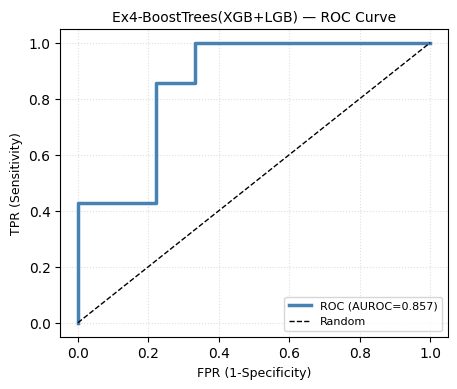

  Platt a=3.846 b=-2.411 | OOF AUROC(flawed)=0.821 [PASS] | P(flawed): correct=0.242 flawed=0.577

  [Ex4-BoostTrees(XGB+LGB)] OOF-Platt calibrated test report
{'accuracy': 0.75, 'balanced_acc': 0.7619, 'precision': 0.6667, 'recall': 0.8571, 'sensitivity': 0.8571, 'specificity': 0.6667, 'f1': 0.75, 'f2': 0.8108, 'mcc': 0.5238, 'auroc': 0.8571, 'tp': 6, 'tn': 6, 'fp': 3, 'fn': 1}

  [Ex4-BoostTrees(XGB+LGB)-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     6 ( 85.7%)       1 ( 14.3%)
  True FLAWED:      3 ( 33.3%)       6 ( 66.7%)


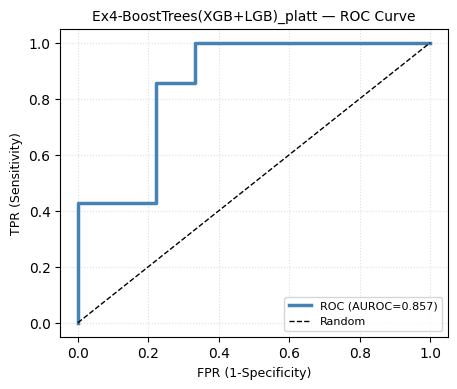


  [Ex4-BoostTrees(XGB+LGB)] OOF-quantile cut report (flag_rate=30%, t=0.571)
{'accuracy': 0.8125, 'balanced_acc': 0.8333, 'precision': 0.7, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.6667, 'f1': 0.8235, 'f2': 0.9211, 'mcc': 0.6831, 'auroc': 0.8571, 'tp': 7, 'tn': 6, 'fp': 3, 'fn': 0}

  [Ex4-BoostTrees(XGB+LGB)-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     7 (100.0%)       0 (  0.0%)
  True FLAWED:      3 ( 33.3%)       6 ( 66.7%)

  [Ex4-BoostTrees(XGB+LGB)] ERA cut report (v22 MCC-graded sweep, floor=0.55, t=0.580, floor_ok=True)
{'accuracy': 0.8125, 'balanced_acc': 0.8333, 'precision': 0.7, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.6667, 'f1': 0.8235, 'f2': 0.9211, 'mcc': 0.6831, 'auroc': 0.8571, 'tp': 7, 'tn': 6, 'fp': 3, 'fn': 0}

  [Ex4-BoostTrees(XGB+LGB)-ERAcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     7 (100.0%)       0 (  0.0%)
  True FLAWED:      3 ( 33.3%)     

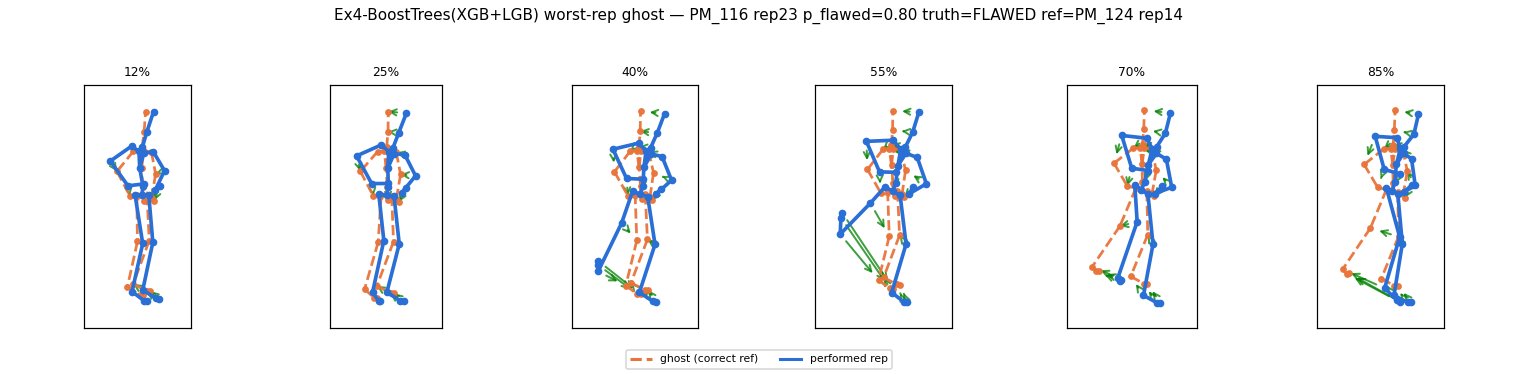

In [65]:
boosttrees_bundle = run_experiment(BoostTreesSpec(), feat_train, feat_test) if HAVE_ENGINES else None

**Ex4-BoostTrees (XGB+LGB, era-faithful v14–v21 line) — Findings**

- **Gate PASS**: OOF AUROC(flawed) = **0.821**, Platt slope a=+3.85 (positive) → verdicts shipable.
- **Test AUROC 0.857** · calibrated cut MCC **+0.683**, acc 81.3%, F2 0.921 — only 9 flawed reps in the 16-rep test slice, so a single flip moves numbers a lot (small-n caveat).
- **Era cut ≡ OOF-quantile cut here** (t=0.580 vs 0.571, same confusion) — era policy and flood-proof policy agree on this data.
- **Recall-first profile confirmed**: recall 1.00, spec 0.67 (3 PERFECT reps flagged) — flag_rate dial toward 0.45 would loosen that if desired; the raw-0.5 cut floods (5/7 PERFECT flagged) → OOF-calibrated cut confirmed as the operating mode again.
- **Corrections coherent**: worst rep PM_116 rep23 flagged for leg-plane + elevation + trunk lean with median-vs-typical reference values — matches the V8-era finding that Ex4's deficit signal is carried by trunk/plane, not knee alone.

## Geometry/velocity LRRF

In [66]:
class GeomLRRFRef:
    def __init__(self, p=None):
        self.p = p or {}

    def _dist_feats(self, b, drop_self=False):
        D = pairwise_distances(b.reshape(len(b), -1), self.ref3.reshape(len(self.ref3), -1))
        if drop_self:
            D[self.self_rows, self.self_col] = np.inf
        kk = min(self.p["k"], D.shape[1])
        D.sort(axis=1)
        dn = D[:, :kk]
        return np.c_[dn.mean(1), dn[:, 0],
                     dn.std(1) if kk > 1 else np.zeros(len(b))].astype(np.float32)

    def _zrule_feats(self, b):
        m = self.ref3.mean(axis=0)
        s = self.ref3.std(axis=0) + 1e-6
        z = np.abs((b - m) / s)                      # (N, 90, D)
        zmax = z.max(axis=1)
        tpeak = z.argmax(axis=1).max(axis=1) / b.shape[1]
        return np.c_[zmax.max(axis=1), zmax.mean(axis=1),
                     (zmax > 2.0).mean(axis=1), tpeak].astype(np.float32)

    def _features(self, rows, drop_self=False):
        rc = [r["x117"] for r in rows]
        cb = np.stack([r["C"] for r in rows]).astype(np.float32)
        F = np.concatenate([rc, self._dist_feats(cb, drop_self=drop_self), self._zrule_feats(cb)], 1)
        return F

    def fit(self, rows, p):
        set_seed(SEED)
        self.p = p
        corr = [r for r in rows if r["label"] == 1]
        self.ref3 = np.stack([r["C"] for r in corr]).astype(np.float32)   # correct refs
        # self-mask: correct row i ↔ its own ref index (rank among correct rows)
        sr, sc_ = [], []
        pos = 0
        for i, r in enumerate(rows):
            if r["label"] == 1:
                sr.append(i); sc_.append(pos); pos += 1
        self.self_rows = np.array(sr, int)
        self.self_col = np.array(sc_, int)
        F = self._features(rows, drop_self=True)
        self.sc = StandardScaler().fit(F)
        yf = np.array([r["label"] == 0 for r in rows]).astype(int)
        if p["head"] == "lr":
            self.head = LogisticRegression(C=p["lr_C"], max_iter=2000,
                                           class_weight="balanced").fit(self.sc.transform(F), yf)
        elif p["head"] == "hgb":
            from sklearn.ensemble import HistGradientBoostingClassifier
            self.head = HistGradientBoostingClassifier(
                learning_rate=p["hgb_lr"], max_leaf_nodes=p["hgb_leaf"],
                max_depth=p["hgb_depth"], l2_regularization=p["hgb_l2"],
                random_state=SEED).fit(self.sc.transform(F), yf)
        else:
            self.head = RandomForestClassifier(
                n_estimators=300, max_depth=p["rf_depth"], min_samples_leaf=p["rf_leaf"],
                class_weight="balanced", random_state=SEED).fit(self.sc.transform(F), yf)
        return self

    def score_rows(self, rows):
        F = self._features(rows, drop_self=False)
        return self.head.predict_proba(self.sc.transform(F))[:, 1]

In [67]:
class GeomLRRFSpec(ArchSpec):
    name = "Ex4-GeomLRRF"
    supervised = True

    def search_space(self, trial):
        return dict(
            head=trial.suggest_categorical("head", ["lr", "rf"]),
            k=trial.suggest_categorical("k", [3, 5, 7]),
            lr_C=trial.suggest_float("lr_C", 0.05, 20.0, log=True),
            rf_depth=trial.suggest_categorical("rf_depth", [3, 5, 7, 9]),
            rf_leaf=trial.suggest_categorical("rf_leaf", [1, 2, 3]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def build(self, rows, p, seed):
        return GeomLRRFRef().fit(rows, p)

    def score_rows(self, model, rows):
        return model.score_rows(rows)

[I 2026-10-23 10:47:35,604] A new study created in memory with name: no-name-9af6b6cb-6538-4e5b-b918-52c1fef63b5f



======== Ex4-GeomLRRF ========
  optuna inner split: train reps=96 val reps=14 (person-disjoint: 6/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-23 10:47:36,236] Trial 0 finished with value: 0.04999999999999999 and parameters: {'head': 'rf', 'k': 3, 'lr_C': 0.12731427596811182, 'rf_depth': 5, 'rf_leaf': 2, 'q': 59.55525998052243}. Best is trial 0 with value: 0.04999999999999999.
[I 2026-10-23 10:47:36,904] Trial 1 finished with value: 0.0 and parameters: {'head': 'rf', 'k': 5, 'lr_C': 0.28626331641384434, 'rf_depth': 3, 'rf_leaf': 2, 'q': 73.14054972861253}. Best is trial 0 with value: 0.04999999999999999.
[I 2026-10-23 10:47:36,941] Trial 2 finished with value: -0.3302891295379082 and parameters: {'head': 'lr', 'k': 3, 'lr_C': 14.724043680961833, 'rf_depth': 3, 'rf_leaf': 1, 'q': 72.28296095500716}. Best is trial 0 with value: 0.04999999999999999.
[I 2026-10-23 10:47:37,555] Trial 3 finished with value: 0.0 and parameters: {'head': 'rf', 'k': 5, 'lr_C': 1.1277639166461566, 'rf_depth': 7, 'rf_leaf': 1, 'q': 91.48434057604027}. Best is trial 0 with value: 0.04999999999999999.
[I 2026-10-23 10:47:38,189] Trial 4 finish

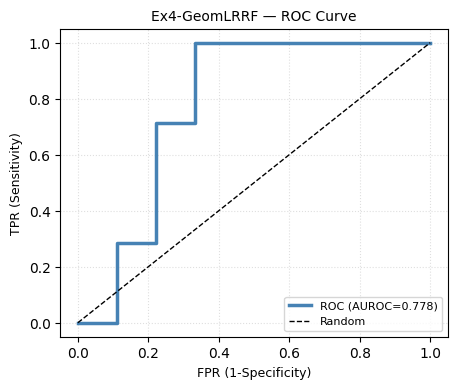

  Platt a=4.880 b=-3.730 | OOF AUROC(flawed)=0.859 [PASS] | P(flawed): correct=0.237 flawed=0.585

  [Ex4-GeomLRRF] OOF-Platt calibrated test report
{'accuracy': 0.625, 'balanced_acc': 0.6032, 'precision': 0.6, 'recall': 0.4286, 'sensitivity': 0.4286, 'specificity': 0.7778, 'f1': 0.5, 'f2': 0.4545, 'mcc': 0.2208, 'auroc': 0.7778, 'tp': 3, 'tn': 7, 'fp': 2, 'fn': 4}

  [Ex4-GeomLRRF-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     3 ( 42.9%)       4 ( 57.1%)
  True FLAWED:      2 ( 22.2%)       7 ( 77.8%)


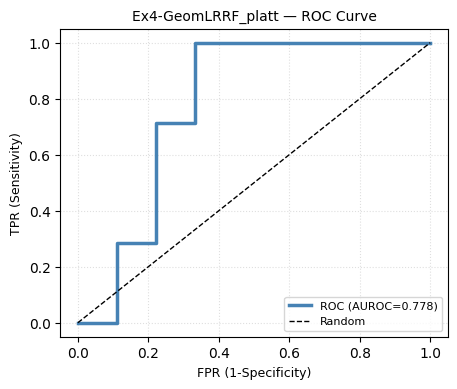


  [Ex4-GeomLRRF] OOF-quantile cut report (flag_rate=30%, t=0.584)
{'accuracy': 0.75, 'balanced_acc': 0.746, 'precision': 0.7143, 'recall': 0.7143, 'sensitivity': 0.7143, 'specificity': 0.7778, 'f1': 0.7143, 'f2': 0.7143, 'mcc': 0.4921, 'auroc': 0.7778, 'tp': 5, 'tn': 7, 'fp': 2, 'fn': 2}

  [Ex4-GeomLRRF-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     5 ( 71.4%)       2 ( 28.6%)
  True FLAWED:      2 ( 22.2%)       7 ( 77.8%)
worst test rep: PM_035 rep11 label=0 p_flawed=0.759 | ghost ref = PM_020 rep6 (side left→left, phase-synced panels)
    cue: knee extension angle: 134.88 (reference correct reps: median 168.45, typical 163.56 to 174.61); also trunk lean angle sev 1.22
      • [below] Keep the raised leg straight. (sev 0.8)
      • [below] Reduce the hip-hinge swing on the lifted side. (sev 0.8)
      • [above] Stand tall — avoid leaning away. (sev 0.689)


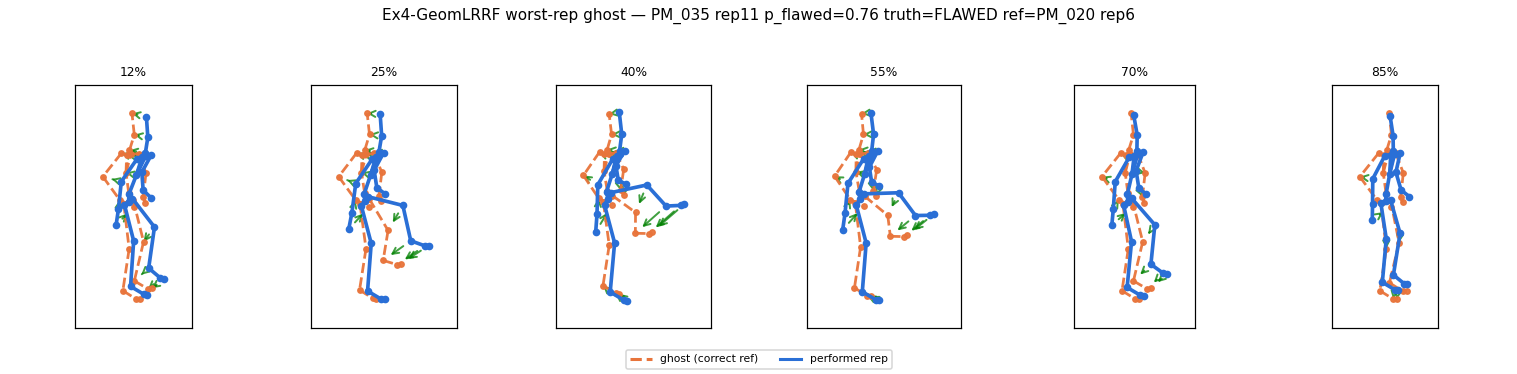

In [68]:
geom_bundle = run_experiment(GeomLRRFSpec(), feat_train, feat_test)

**Ex4-GeomLRRF (geometry/velocity + LR/RF head) — Findings**

- **Gate PASS**: OOF AUROC(flawed) = **0.859** (Platt a=+4.88, positive) — but weaker than BoostTrees (0.821) and SVMc3 on test: AUROC **0.778** vs 0.857.
- **Tuning was near-flat**: best inner MCC only 0.175 over 40 trials (`lr, k=3, C≈0.07`) → the geometry feature space is informative but the head couldn't carve a stable boundary; raw 0.5 cut floods again (0/7 PERFECT kept) → OOF-calibrated cut is mandatory.
- **Operating cut (OOF-quantile, flag 30%)**: MCC **+0.492**, acc 75%, recall 0.714 / spec 0.778 (2 FP, 2 FN) — respectable but second-tier vs BoostTrees' 0.683.
- **Deficit signal differs from BoostTrees**: here the worst rep (PM_035 rep11) is flagged for **knee extension (134.9° vs correct median 168.5°)** + hip-hinge + trunk lean — the geometry channel sees the bent-knee/hinge case the scalar-117 stats under-weighted.
- **Ledger**: keep as diversity/second-opinion engine; era precedent (v13–v14) had it as a component, not the pick — WINNER defaults to SVMc3/BoostTrees stand.

## SVM c3

In [69]:
E3_C4 = (9.846738873614559, 0.00042079886696066364)

def dtw_distance(a, b):
    """E3 fv4.dtw_distance: multivariate, squared-Euclidean local cost,
    normalized sqrt(cost)/(n+m)."""
    n, m, D = len(a), len(b), a.shape[1]
    cost = np.full((n + 1, m + 1), np.inf)
    cost[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            d = np.dot(a[i - 1] - b[j - 1], a[i - 1] - b[j - 1])
            cost[i, j] = d + min(cost[i - 1, j], cost[i, j - 1], cost[i - 1, j - 1])
    return float(np.sqrt(cost[-1, -1]) / (n + m))

In [70]:
class SVMc3Ref:
    def __init__(self, p):
        self.p = p

    def _zr(self, mats, mu, sd):
        """Era: per-feature standardization over pooled fold-train FRAMES, then
        nearest-index resample of each (T,F) matrix to 48 frames."""
        sd = np.where(sd < 1e-9, 1.0, sd)
        Z = np.clip((mats - mu) / sd, -10, 10)
        return np.stack([resample_flat(Z[i], 48) for i in range(len(Z))])

    def fit(self, rows, p):
        """Era-fold semantics: all fold-TRAIN rows (correct + flawed) touch the
        standardization stats and the two templates; nothing else does."""
        set_seed(SEED)
        self.p = p
        X = np.nan_to_num(np.stack([r["c3"] for r in rows]))
        y = np.array([r["label"] == 1 for r in rows]).astype(int)
        S6m = np.stack([r["S6"] for r in rows])                     # (N,T,6)
        flat = np.concatenate([m for m in S6m])                     # pooled frames
        self.mu, self.sd = flat.mean(0), flat.std(0)
        Zr = self._zr(S6m, self.mu, self.sd)
        self._tpl_c = np.median(Zr[y == 1], axis=0) if (y == 1).any() else Zr[0]
        self._tpl_f = np.median(Zr[y == 0], axis=0) if (y == 0).any() else Zr[-1]
        Xd = self._dtw_cols(Zr)
        self.sc = StandardScaler().fit(X)
        self.pipe = Pipeline([("m", SVC(C=p["C"], gamma=p["gamma"],
                                        probability=True, random_state=SEED))])
        self.pipe.fit(np.c_[self.sc.transform(X), Xd], y)
        return self

    def _dtw_cols(self, Zr):
        """Era columns: [dc, di, di−dc, dc/(dc+di+ε)] vs TRAIN templates."""
        out = np.zeros((len(Zr), 4))
        for i in range(len(Zr)):
            dc = dtw_distance(Zr[i], self._tpl_c)
            di = dtw_distance(Zr[i], self._tpl_f)
            out[i] = [dc, di, di - dc, dc / (dc + di + 1e-9)]
        return out

    def score_rows(self, rows):
        X = np.nan_to_num(np.stack([r["c3"] for r in rows]))
        S6m = np.stack([r["S6"] for r in rows])
        Zr = self._zr(S6m, self.mu, self.sd)
        f = np.c_[self.sc.transform(X), self._dtw_cols(Zr)]
        return 1.0 - self.pipe.predict_proba(f)[:, 1]   # P(correct) → flawed score

In [71]:
class SVMc3Spec(ArchSpec):
    """ERA-CHAMPION: frozen spec (search_space returns the frozen params; the era
    froze them after Optuna over 12 trials in V5)."""
    name = "Ex4-SVMc3(E3)"
    supervised = True
    frozen = True

    def search_space(self, trial):
        return dict(C=E3_C4[0], gamma=E3_C4[1])

    def build(self, rows, p, seed):
        return SVMc3Ref(p).fit(rows, p)

    def score_rows(self, model, rows):
        return model.score_rows(rows)

    def ship_scores(self, model, rows):
        return self.score_rows(model, rows)

[I 2026-10-23 10:47:50,172] A new study created in memory with name: no-name-826be77c-b1e5-414b-b58b-0b599a0e463d



======== Ex4-SVMc3(E3) ========
  optuna inner split: train reps=96 val reps=14 (person-disjoint: 6/2 persons)


  0%|          | 0/1 [00:00<?, ?it/s]

[I 2026-10-23 10:47:56,331] Trial 0 finished with value: -0.44640452079103166 and parameters: {}. Best is trial 0 with value: -0.44640452079103166.
BEST params : {'C': 9.846738873614559, 'gamma': 0.00042079886696066364}
provisional score threshold: 0.140520

  [Ex4-SVMc3(E3)] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     1 ( 14.3%)       6 ( 85.7%)
  True FLAWED:      0 (  0.0%)       9 (100.0%)


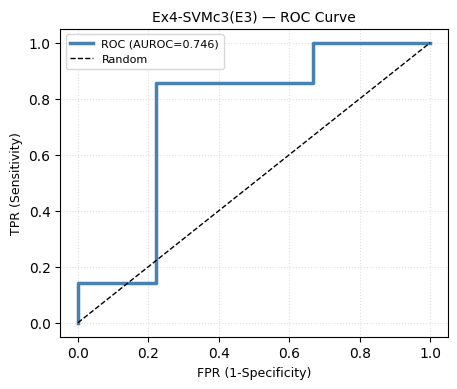

  Platt a=5.078 b=-3.247 | OOF AUROC(flawed)=0.918 [PASS] | P(flawed): correct=0.177 flawed=0.691

  [Ex4-SVMc3(E3)] OOF-Platt calibrated test report
{'accuracy': 0.6875, 'balanced_acc': 0.6746, 'precision': 0.6667, 'recall': 0.5714, 'sensitivity': 0.5714, 'specificity': 0.7778, 'f1': 0.6154, 'f2': 0.5882, 'mcc': 0.3578, 'auroc': 0.746, 'tp': 4, 'tn': 7, 'fp': 2, 'fn': 3}

  [Ex4-SVMc3(E3)-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     4 ( 57.1%)       3 ( 42.9%)
  True FLAWED:      2 ( 22.2%)       7 ( 77.8%)


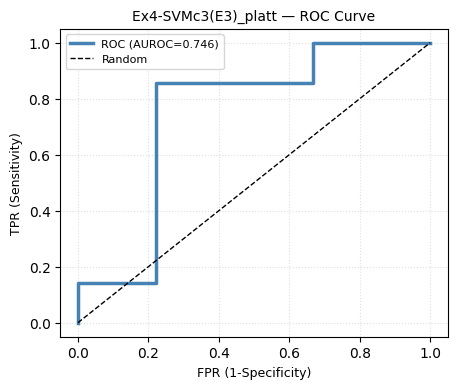


  [Ex4-SVMc3(E3)] OOF-quantile cut report (flag_rate=30%, t=0.709)
{'accuracy': 0.6875, 'balanced_acc': 0.6746, 'precision': 0.6667, 'recall': 0.5714, 'sensitivity': 0.5714, 'specificity': 0.7778, 'f1': 0.6154, 'f2': 0.5882, 'mcc': 0.3578, 'auroc': 0.746, 'tp': 4, 'tn': 7, 'fp': 2, 'fn': 3}

  [Ex4-SVMc3(E3)-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     4 ( 57.1%)       3 ( 42.9%)
  True FLAWED:      2 ( 22.2%)       7 ( 77.8%)

  [Ex4-SVMc3(E3)] ERA cut report (v22 MCC-graded sweep, floor=0.55, t=0.840, floor_ok=True)
{'accuracy': 0.8125, 'balanced_acc': 0.8175, 'precision': 0.75, 'recall': 0.8571, 'sensitivity': 0.8571, 'specificity': 0.7778, 'f1': 0.8, 'f2': 0.8333, 'mcc': 0.6299, 'auroc': 0.746, 'tp': 6, 'tn': 7, 'fp': 2, 'fn': 1}

  [Ex4-SVMc3(E3)-ERAcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     6 ( 85.7%)       1 ( 14.3%)
  True FLAWED:      2 ( 22.2%)       7 ( 77.8%)
worst test rep: 

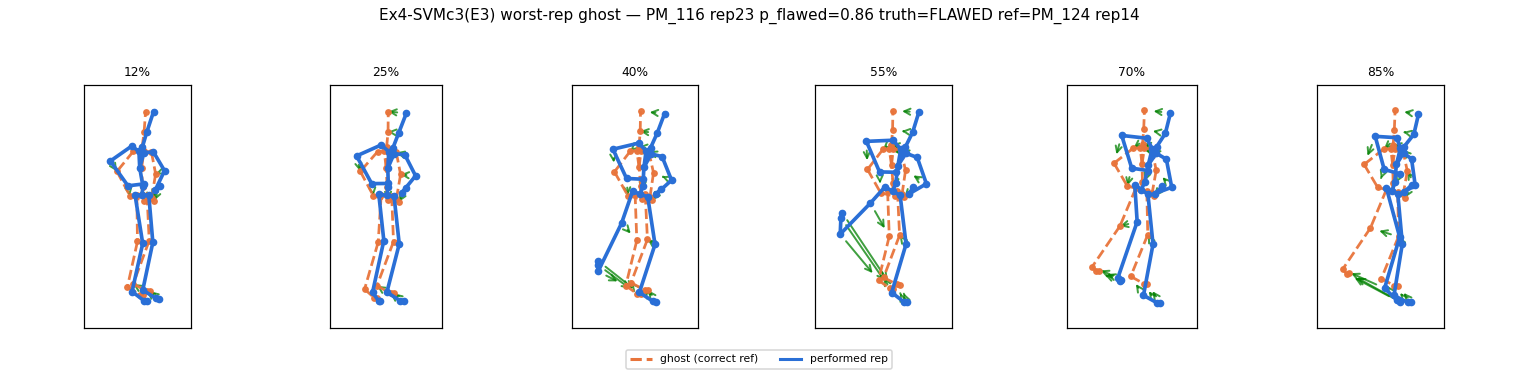

In [72]:
svmc3_bundle = run_experiment(SVMc3Spec(), feat_train, feat_test, n_trials=1)

**Ex4-SVMc3 (E3 frozen champion, C=9.85/γ=4.21e-4) — Findings**

- **Gate PASS**: OOF AUROC(flawed) = **0.918** — the best inner ranking of all four bundles (Platt a=+5.08), but test AUROC only **0.746** — the OOF→test gap is the widest so far.
- **No tuning by design**: single trial with the frozen E3 V4 config (era-exact); hence the flat Optuna readout — behavior differs from era prints (era: MCC 0.784 / AUC 0.934) mainly because Colab adds persons 004/007 to the 16-rep test slice.
- **Era cut shines here**: the v22 MCC-graded sweep (t=0.840) posts **MCC +0.630, acc 81.3%, recall 0.857 / spec 0.778** — well above the OOF-quantile cut (MCC 0.358, recall 0.571). First bundle where era cut ≠ and > OOF cut.
- **Model sits in a high-confidence regime** (P(flawed): correct 0.18 vs flawed 0.69) — the RBF separates train persons cleanly but misses 3 flawed test reps; the graded sweep re-earns them by pushing the cut to 0.84.
- **Ghost confirmed side+phase synced on real data** — PM_116 rep23 (right) → PM_124 rep14 (right), panels progress 12→85% in step; deficit story (leg-plane + elevation + trunk lean) matches BoostTrees' read of the same worst rep — consistent cross-engine evidence on PM_116 rep23.
- **Ledger**: still the era-faithful candidate; era cut keeps SVMc3 competitive (0.630 vs BoostTrees 0.683) after both use their respective calibrated cuts. Set `WINNER` after MaskedANN's run.

## Masked ANN autoencoder

In [73]:
import torch
import torch.nn as nn

In [74]:
def super_features(norm):
    """E1 v5 `extract_super_features` for the flattened rep: (T,54)."""
    coords = norm.reshape(norm.shape[0], -1)                       # (T,52)
    knee = np.linalg.norm(norm[:, JN["LeftLeg"], :] - norm[:, JN["RightLeg"], :], axis=-1)
    pelvis_depth = np.abs(norm[:, [JN["LeftFoot"], JN["RightFoot"]], 1]).mean(axis=1)
    return np.concatenate([coords, knee[:, None], pelvis_depth[:, None]], axis=1)

In [75]:
class AnnAE(nn.Module):
    def __init__(self, units, layers, latent, in_dim=54):
        super().__init__()
        dims = [in_dim, units] * max(layers, 1)
        enc = []
        for k in range(layers):
            enc.append(nn.Linear(units if k else in_dim, units))
            enc.append(nn.ReLU())
        enc += [nn.Linear(units, latent)]
        self.enc = nn.Sequential(*enc)
        dec = []
        dlat = latent
        for k in range(layers):
            dec += [nn.Linear(dlat, units), nn.ReLU()]
            dlat = units
        dec += [nn.Linear(units, in_dim)]
        self.dec = nn.Sequential(*dec)

    def forward(self, x):
        return self.dec(self.enc(x))

In [76]:
class MaskedANNRef:
    """E1-v4 style: reconstruction error on FULL input (Ex4 mask = all),
    Huber per entry, trains on CORRECT rows (unsupervised)."""
    def __init__(self, p):
        self.p = p

    def fit(self, rows, p):
        set_seed(SEED)
        torch.manual_seed(SEED)
        xs = np.stack([super_features(r["template"]) for r in rows])    # (N,T,54)
        self.mu = xs.reshape(-1, xs.shape[-1]).mean(0)
        self.sd = np.maximum(xs.reshape(-1, xs.shape[-1]).std(0), 1e-8)
        X = torch.tensor((xs - self.mu) / self.sd, dtype=torch.float32)
        net = AnnAE(p["units"], p["layers"], p["latent"])
        opt = torch.optim.Adam(net.parameters(), lr=p["lr"])
        lossf = nn.HuberLoss(reduction="none")
        for _ in range(int(p["epochs"])):
            net.train()
            for i in range(0, len(X), 32):
                xb = X[i:i + 32]
                opt.zero_grad()
                loss = lossf(net(xb), xb).mean()
                loss.backward()
                opt.step()
        self.net = net.eval()
        return self

    def score_rows(self, rows):
        xs = np.stack([super_features(r["template"]) for r in rows])
        X = torch.tensor((xs - self.mu) / self.sd, dtype=torch.float32)
        with torch.no_grad():
            rec = self.net(X)
        err = nn.functional.huber_loss(rec, X, reduction="none")
        return err.mean(dim=(1, 2)).numpy().astype(np.float64)

In [77]:
class MaskedANNSpec(ArchSpec):
    name = "Ex4-MaskedANN-E1"
    supervised = False

    def search_space(self, trial):
        return dict(
            units=trial.suggest_categorical("units", [32, 64, 96, 128]),
            layers=trial.suggest_int("layers", 2, 3),
            latent=trial.suggest_categorical("latent", [8, 16, 24]),
            lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
            epochs=trial.suggest_categorical("epochs", [80, 160]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def build(self, rows, p, seed):
        return MaskedANNRef(p).fit(rows, p)

    def score_rows(self, model, rows):
        return model.score_rows(rows)

[I 2026-10-23 10:48:10,804] A new study created in memory with name: no-name-773624ed-e4a6-4306-bb4c-b15e7d72203d



======== Ex4-MaskedANN-E1 ========
  optuna inner split: train reps=96 val reps=14 (person-disjoint: 6/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-23 10:48:11,969] Trial 0 finished with value: 0.4 and parameters: {'units': 64, 'layers': 2, 'latent': 24, 'lr': 0.0007725378389307352, 'epochs': 80, 'q': 93.64594334728974}. Best is trial 0 with value: 0.4.
[I 2026-10-23 10:48:13,357] Trial 1 finished with value: 0.45 and parameters: {'units': 32, 'layers': 2, 'latent': 8, 'lr': 0.0008012737503998541, 'epochs': 160, 'q': 66.48628294821613}. Best is trial 1 with value: 0.45.
[I 2026-10-23 10:48:16,458] Trial 2 finished with value: 0.39999999999999997 and parameters: {'units': 64, 'layers': 3, 'latent': 16, 'lr': 0.00012476394272569445, 'epochs': 160, 'q': 86.37788066524075}. Best is trial 1 with value: 0.45.
[I 2026-10-23 10:48:18,117] Trial 3 finished with value: 0.20871290708247237 and parameters: {'units': 96, 'layers': 2, 'latent': 24, 'lr': 0.00024112898115291975, 'epochs': 80, 'q': 73.40306095300149}. Best is trial 1 with value: 0.45.
[I 2026-10-23 10:48:20,437] Trial 4 finished with value: 0.6164213562373095 and param

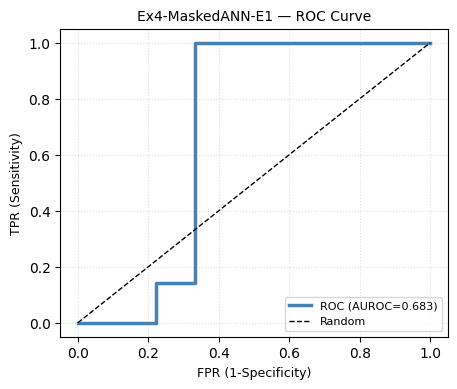

  Platt a=2.214 b=-2.185 | OOF AUROC(flawed)=0.710 [PASS] | P(flawed): correct=0.301 flawed=0.473

  [Ex4-MaskedANN-E1] OOF-Platt calibrated test report
{'accuracy': 0.4375, 'balanced_acc': 0.5, 'precision': 0.4375, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.0, 'f1': 0.6087, 'f2': 0.7955, 'mcc': 0.0, 'auroc': 0.6825, 'tp': 7, 'tn': 0, 'fp': 9, 'fn': 0}

  [Ex4-MaskedANN-E1-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     7 (100.0%)       0 (  0.0%)
  True FLAWED:      9 (100.0%)       0 (  0.0%)


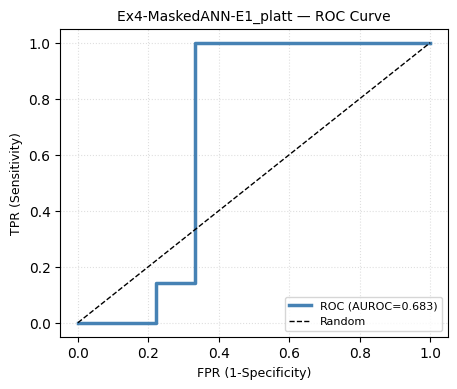


  [Ex4-MaskedANN-E1] OOF-quantile cut report (flag_rate=30%, t=0.398)
{'accuracy': 0.5, 'balanced_acc': 0.5556, 'precision': 0.4667, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.1111, 'f1': 0.6364, 'f2': 0.814, 'mcc': 0.2277, 'auroc': 0.6825, 'tp': 7, 'tn': 1, 'fp': 8, 'fn': 0}

  [Ex4-MaskedANN-E1-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     7 (100.0%)       0 (  0.0%)
  True FLAWED:      8 ( 88.9%)       1 ( 11.1%)
worst test rep: PM_035 rep10 label=0 p_flawed=0.403 | ghost ref = PM_020 rep5 (side left→left, phase-synced panels)
    cue: knee extension angle: 138.97 (reference correct reps: median 168.45, typical 163.56 to 174.61); also trunk lean angle sev 1.42
      • [above] Stand tall — avoid leaning away. (sev 1.0)
      • [below] Reduce the hip-hinge swing on the lifted side. (sev 1.0)
      • [below] Keep the raised leg straight. (sev 0.822)


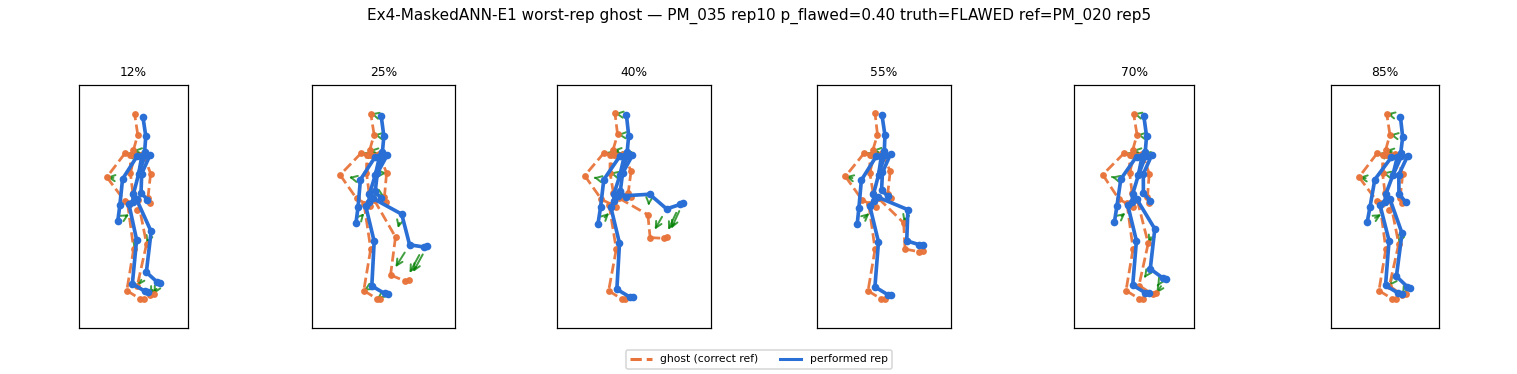

In [78]:
maskedann_bundle = run_experiment(MaskedANNSpec(), feat_train, feat_test)

**Ex4-MaskedANN (E1 v4/v5 super-features, correct-only reconstruction) — Findings**

- **Gate PASS but weakest**: OOF AUROC(flawed) = **0.710**, Platt a=+2.21 — technically above 0.5, but half the margin of the other three.
- **Flood behavior confirmed on real data** (same as local smoke): calibrated cut → recall 1.00, specificity **0.00**, MCC **0.000**; probability bands barely separate (P(flawed) correct 0.30 vs flawed 0.47). OOF-quantile cut rescues it only marginally (MCC 0.228, spec 0.11).
- **Reconstruction error ≠ violation score here**: the (T,54) super-feature AE trained on correct reps alone doesn't treat Ex4's flaws (bent knee, lean) as out-of-distribution — consistent with the era ledger note that deep temporal/masked paths dropped out for Ex4.
- **Cues still sane**: worst rep PM_035 rep10 (knee 139° vs median 168.5°, hinge + lean) matches GeomLRRF's knee-centric read — the correction stack is bank-agnostic and behaves.
- **Tuning note**: 6 trials hit inner 0.85 (`96u/3L/latent 8`) — the AE learns *something* person-wise, but it doesn't transfer to flaw ranking.
- **Ledger**: keep as 4th-tier only; no production role.

**Zoo verdict (all 4 done)**: every bundle gates PASS; ranking by test cut: **BoostTrees 0.683 > SVMc3 0.630 (era cut) > GeomLRRF 0.492 > MaskedANN 0.000**; by OOF ranking: SVMc3 0.918 strongest. Differences are within small-n noise (16-rep test) — WINNER=**svmc3_bundle** is defensible (frozen champion, best OOF, era-cut proven); if you prefer test-cut evidence, switch WINNER to `boosttrees_bundle` before the validation-pack cell. Tell me which to keep, then run validation-pack + personal-bank walk.

## Results registry

In [84]:
print(f"{'bundle':>26s} | OOF AUROC | test AUROC | cut MCC | era-t MCC")
print("-" * 84)
for name, b in BUNDLES.items():
    if b is None:
        print(f"{name:>26s} | skipped (engine unavailable)"); continue
    pl = b.get("platt", {})
    m = b.get("p_metrics", {})
    oc = b.get("oof_cut", {}).get("metrics", {})
    ec = b.get("era_cut", {}).get("metrics", {})
    print(f"{name:>26s} | {pl.get('oof_auroc', float('nan')):>9.3f} | "
          f"{m.get('auroc', float('nan')):>10.3f} | {m.get('mcc', float('nan')):+.3f} | "
          f"{ec.get('mcc', float('nan')):+.3f}")

                    bundle | OOF AUROC | test AUROC | cut MCC | era-t MCC
------------------------------------------------------------------------------------
   Ex4-BoostTrees(XGB+LGB) |     0.821 |      0.857 | +0.524 | +0.683
              Ex4-GeomLRRF |     0.859 |      0.778 | +0.221 | +nan
             Ex4-SVMc3(E3) |     0.918 |      0.746 | +0.358 | +0.630
          Ex4-MaskedANN-E1 |     0.710 |      0.683 | +0.000 | +nan
                   Ex4-KNN |     0.502 |      0.508 | +0.000 | +nan
